# 04 · Why long tasks fail: compounding errors and time horizons
Level L1 · Part 1 · core · ~25 min · builds on 01

## Goal
By the end you can simulate 1,000 agent runs of 10, 50 and 300 steps at 95%, 99% and 99.9% per-step success with NumPy, explain why the long runs collapse, and read a METR-style time-horizon chart, including why horizons above ~16 hours are not yet reliable.

## The idea
In lesson 01 the agent needed two actions to resolve issue #3. Real work on Pocket Tracker takes many more: open the page, find the issue, read the code, edit, run the tests, close the issue, and so on. A run succeeds only if **every** step works, so the chances multiply. That is **compounding error**: a per-step success rate that sounds great (95%) becomes a run success rate that is terrible (under 1% at 100 steps).

Analogy: a relay race with 50 runners. Each drops the baton only 1 time in 20, yet most races end with a dropped baton.

A **time horizon** turns this into one number for a model: the length of task (in human working time) it finishes half the time.

## Picture
```mermaid
flowchart LR
  S1[step 1<br/>p] --> S2[step 2<br/>p] --> S3[...] --> SN[step n<br/>p] --> OK([run succeeds<br/>p x p x ... = p^n])
  S1 -. fails .-> X([run fails])
  S2 -. fails .-> X
  SN -. fails .-> X
```

## Step by step

### 1. One run, one step at a time
We model one Pocket Tracker job as a chain of steps. Each step succeeds with probability `p` (the **step reliability**). We draw a random number per step with NumPy; the step works if the number is below `p`. The run fails at the first broken step. The seed makes the output the same every time.

In [1]:
import numpy as np

rng = np.random.default_rng(seed=4)
p, n_steps = 0.95, 10
steps_ok = rng.random(n_steps) < p          # one True/False per step
print("steps ok:", steps_ok.astype(int))
print("run succeeded:", steps_ok.all())

steps ok: [1 1 0 1 1 1 1 1 1 1]
run succeeded: False


One run tells you little. The next cell repeats the same 10-step job 1,000 times: a 2-D array, one row per run, one column per step. A run counts only if its whole row is `True`.

In [2]:
runs = 1000
grid = rng.random((runs, n_steps)) < p
run_ok = grid.all(axis=1)                    # True only if every step in the row worked
print(f"{run_ok.sum()} of {runs} runs succeeded ({run_ok.mean():.1%})")
print(f"average step success: {grid.mean():.1%}")

595 of 1000 runs succeeded (59.5%)
average step success: 94.8%


About 95% of steps worked, but only about 60% of runs. The step rate and the run rate are different numbers.

### 2. The full grid: 10, 50 and 300 steps
Now the lesson's experiment: 1,000 runs for each step count and each step reliability. Next to each simulated rate we print `p ** n`, the exact chance that `n` independent steps all succeed.

In [3]:
print(f"{'p':>6} {'steps':>6} {'simulated':>10} {'p**n':>10}")
for p in [0.95, 0.99, 0.999]:
    for n in [10, 50, 300]:
        simulated = (rng.random((runs, n)) < p).all(axis=1).mean()
        print(f"{p:>6} {n:>6} {simulated:>10.1%} {p ** n:>10.1%}")

     p  steps  simulated       p**n
  0.95     10      60.7%      59.9%
  0.95     50       7.8%       7.7%
  0.95    300       0.0%       0.0%
  0.99     10      90.5%      90.4%
  0.99     50      62.5%      60.5%
  0.99    300       4.7%       4.9%
 0.999     10      99.0%      99.0%
 0.999     50      94.7%      95.1%
 0.999    300      69.9%      74.1%


Read across the 300-step column: at 95% per step no run finishes; at 99% about 5% do; even at 99.9% about one run in four fails. The simulation matches `p ** n` to within a few points, so from here we can use the formula and keep the simulation as a check.

### 3. The curves
Plotting `p ** n` against the number of steps shows how quickly each curve falls. The dotted line marks 50%.

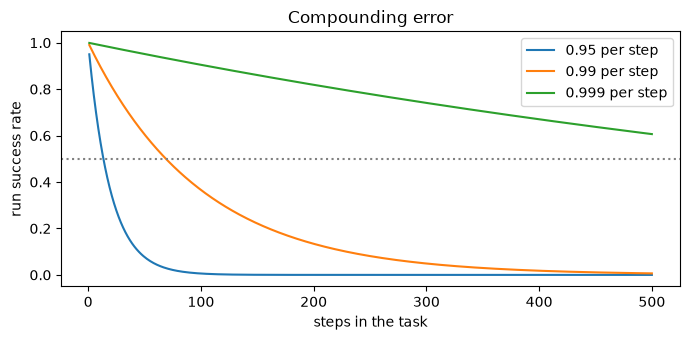

In [4]:
import matplotlib.pyplot as plt

n = np.arange(1, 501)
fig, ax = plt.subplots(figsize=(7, 3.5))
for p in [0.95, 0.99, 0.999]:
    ax.plot(n, p ** n, label=f"{p} per step")
ax.axhline(0.5, ls=":", c="gray")
ax.set(xlabel="steps in the task", ylabel="run success rate", title="Compounding error")
ax.legend(); plt.tight_layout(); plt.show()

Each curve crosses 50% at a different length. That length is the task size the agent finishes half the time. Solving `p ** n = 0.5` gives `n = ln(0.5) / ln(p)`:

In [5]:
for p in [0.95, 0.99, 0.999]:
    half_length = np.log(0.5) / np.log(p)
    print(f"p = {p}: 50% of runs finish at about {half_length:.0f} steps")

p = 0.95: 50% of runs finish at about 14 steps
p = 0.99: 50% of runs finish at about 69 steps
p = 0.999: 50% of runs finish at about 693 steps


Each extra "9" of step reliability makes the 50% length about 10 times longer (14 → 69 → 693 steps). That is why per-step reliability matters so much more than it seems.

### 4. Where runs die
A failed run does not fail at the end; it fails at its first broken step, and every step after that is wasted work (and money). For the 50-step job at 95%, record the step where each run first fails:

In [6]:
grid = rng.random((runs, 50)) < 0.95
failed = ~grid.all(axis=1)
first_fail = np.argmin(grid[failed], axis=1) + 1     # index of the first False, counted from 1
print(f"{failed.sum()} of {runs} runs failed")
print(f"median step of first failure: {np.median(first_fail):.0f}")
print(f"failed by step 10: {(first_fail <= 10).mean():.0%} of the failed runs")

934 of 1000 runs failed
median step of first failure: 13
failed by step 10: 43% of the failed runs


Half of the failed runs had already broken by about step 13, yet a harness without checks would keep going to step 50. This is why long-running agents need checks along the way, not only at the end.

### 5. Grow it: catching errors
Real agents are not pure chains. If a step goes wrong and the agent **notices** (a test fails, the page did not change) it can redo the step. Suppose the agent catches 90% of its errors and redoes the step once. Now a step is lost only if it fails, is not caught, or the retry also fails. We simulate this directly:

In [7]:
p, catch = 0.95, 0.90
first_try = rng.random((runs, 300)) < p
caught = rng.random((runs, 300)) < catch
retry = rng.random((runs, 300)) < p
step_ok = first_try | (caught & retry)               # ok first time, or caught and redone
print(f"effective step reliability: {step_ok.mean():.2%}")
print(f"300-step runs that succeed: {step_ok.all(axis=1).mean():.1%}  (without catching: {p ** 300:.1e})")

effective step reliability: 99.26%
300-step runs that succeed: 10.9%  (without catching: 2.1e-07)


The model did not get better; catching errors raised the effective step reliability from 95% to about 99.3%, and 300-step runs went from impossible to about 11%. Most of this course's long-horizon lessons (tests as verifiers, checkpoints, loop detection) are ways to catch errors.

### 6. Time horizons: one number per model
**METR** (a research group that measures AI models) rates a model by its **50% time horizon**: the length of task, measured by how long it takes a skilled human, that the model completes with 50% success. Facts from METR's work (paper arXiv 2503.14499 and metr.org/time-horizons):
- Claude 3.7 Sonnet had a 50% time horizon of about **50 minutes** (METR paper, March 2025).
- The horizon has been **doubling about every 7 months**.
- METR's time-horizons page is **no longer actively updated** (since 2026-09-08), and it says values **above ~16 hours are unreliable**.

Our step model gives a way to read the number. Treat each human-minute of the task as one step; a 50-minute horizon means the 50% length is 50 steps. Solve for the per-minute reliability:

In [8]:
for horizon_min in [50, 4 * 60, 16 * 60]:
    p_minute = 0.5 ** (1 / horizon_min)              # from p ** horizon = 0.5
    print(f"horizon {horizon_min:>4} min -> per-minute reliability {p_minute:.5f}")

horizon   50 min -> per-minute reliability 0.98623
horizon  240 min -> per-minute reliability 0.99712
horizon  960 min -> per-minute reliability 0.99928


This toy reading is ours, not METR's method (METR measures success on real tasks of known human length). It still shows the scale: a 16-hour horizon means failing in fewer than 1 human-minute in 1,000.

### 7. Reading a time-horizon chart
METR's charts put the date on the x-axis and the horizon on a **log** y-axis, so steady doubling looks like a straight line. We have only one sourced data point, so the line below is an **illustrative trend**: 50 minutes in March 2025, doubled every 7 months. It is not METR's data.

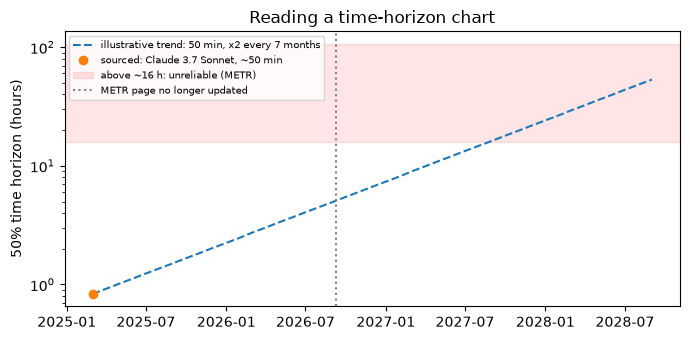

trend crosses 16 h at month 30 after March 2025


In [9]:
months = np.arange(0, 43)                            # months after March 2025
horizon_h = (50 / 60) * 2 ** (months / 7)            # hours
dates = np.datetime64("2025-03") + months.astype("timedelta64[M]")
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(dates, horizon_h, "--", label="illustrative trend: 50 min, x2 every 7 months")
ax.plot(dates[0], horizon_h[0], "o", label="sourced: Claude 3.7 Sonnet, ~50 min")
ax.axhspan(16, horizon_h.max() * 2, color="red", alpha=0.1, label="above ~16 h: unreliable (METR)")
ax.axvline(np.datetime64("2026-09-08"), c="gray", ls=":", label="METR page no longer updated")
ax.set(yscale="log", ylabel="50% time horizon (hours)", title="Reading a time-horizon chart")
ax.legend(fontsize=7, loc="upper left"); plt.tight_layout(); plt.show()
print("trend crosses 16 h at month", int(np.argmax(horizon_h > 16)), "after March 2025")

How to read such a chart: a straight line on a log axis means a constant doubling time; the 50% horizon is not the length of task the model can do *reliably*; and points in the shaded band rest on too little evidence to trust.

### 8. Why long horizons are hard to measure
To measure a 50% horizon at 16 hours you need tasks that take a skilled human 16+ hours, each with a known human time and a reliable grader, and every attempt costs many agent-hours. So there are few of them. With few tasks, the measured success rate is noisy. Here a model's true success on long tasks is exactly 50%; we "measure" it 1,000 times with 5, 20 and 200 tasks:

In [10]:
true_rate = 0.5
for n_tasks in [5, 20, 200]:
    measured = rng.binomial(n_tasks, true_rate, size=1000) / n_tasks
    low, high = np.percentile(measured, [5, 95])
    print(f"{n_tasks:>3} tasks: measured rate between {low:.0%} and {high:.0%} in 90% of tries")
# toy step model: a 16 h task measured at rate r gives a 50% horizon of 16 * ln(0.5) / ln(r)
for r in [0.2, 0.5, 0.8]:
    print(f"16 h tasks measured at {r:.0%} -> toy 50% horizon {16 * np.log(0.5) / np.log(r):.0f} h")

  5 tasks: measured rate between 20% and 80% in 90% of tries
 20 tasks: measured rate between 30% and 70% in 90% of tries
200 tasks: measured rate between 44% and 56% in 90% of tries
16 h tasks measured at 20% -> toy 50% horizon 7 h
16 h tasks measured at 50% -> toy 50% horizon 16 h
16 h tasks measured at 80% -> toy 50% horizon 50 h


With 5 tasks, a model whose true rate is 50% can measure anywhere from 20% to 80%, which in our toy model means a horizon anywhere from about 7 to 50 hours. This is the **measurement limit** behind METR's warning.

## At work
- Long builds are split into many short, checkable units: Anthropic's long-running harness gives the agent a JSON feature list (200+ features, each `passes: false` until tested) and a git commit per feature, so one failure costs one feature, not the run → lesson 37.
- Teams add checkpoints, rewind and resumable runs (Claude Code file snapshots, git, session resume) so a failure at step 40 restarts from step 39, not step 1 → lesson 38.
- Harnesses detect loops (repeated identical actions, no progress) and enforce step, time and cost budgets, because failed runs burn steps after the first error → lesson 39.
- Real tasks are long: OSWorld 2.0 tasks take about 318 tool calls each, and vendor benchmark scores disagree, so teams learn to read benchmarks rather than quote them → lesson 48.

## What just happened
- Each step was a random draw below `p`; a run succeeded only if every step did, and 1,000 runs matched `p ** n`.
- At 300 steps: 95% per step gave 0 successes, 99% about 5%, 99.9% about 70–74%.
- The 50% length is `ln(0.5) / ln(p)`: each extra "9" made it about 10 times longer.
- Failed runs broke early (median around step 13 of 50), and catching 90% of errors lifted 95% steps to about 99.3% (300-step runs: about 11%).
- A **50% time horizon** is one number per model; METR's trend doubles about every 7 months, and values above ~16 hours are unreliable because so few long tasks can be measured.

## Common mistakes
Judging an agent by its **step** success rate. The logs say 95% of steps worked, so someone estimates the 50-step success rate as 95%. The assertion compares that guess with the simulated run rate:

In [11]:
grid = rng.random((runs, 50)) < 0.95
guess = grid.mean()                                  # share of good steps
actual = grid.all(axis=1).mean()                     # share of good runs
assert abs(guess - actual) < 0.05, f"step rate {guess:.1%} but run rate {actual:.1%}"

AssertionError: step rate 94.9% but run rate 7.3%

Fix: a run needs all its steps, so measure runs (row-wise `all`) or multiply: `p ** n`.

In [12]:
print(f"run rate {actual:.1%}, formula {0.95 ** 50:.1%}")
assert abs(actual - 0.95 ** 50) < 0.05

run rate 7.3%, formula 7.7%


Second mistake: reading a 50% horizon as "the model can do tasks this long". It succeeds only **half** the time at that length. In our toy step model the 80% length is `ln(0.8) / ln(0.5)`, about one third of the 50% length:

In [13]:
print(f"50% horizon 4 h -> 80% length in this toy model: {4 * np.log(0.8) / np.log(0.5):.1f} h")

50% horizon 4 h -> 80% length in this toy model: 1.3 h


## Try it
What per-step reliability does a 300-step Pocket Tracker job need to succeed **90%** of the time? Compute it with the formula (`p ** 300 = 0.9`), then check it by simulating 1,000 runs with NumPy. Bonus: with that `p`, what is the 50% length in steps?

In [14]:
# your code here

## Key terms
- **step reliability** — the chance that one agent step (one action and its result) works.
- **compounding error** — run success falls as `p ** n` because every step must work; small per-step errors multiply into likely failure over long tasks.
- **time horizon (50%)** — the length of task, in skilled-human working time, that a model completes with 50% success (METR's measure).
- **measurement limit** — the point past which too few, too costly test tasks make a measured success rate or horizon too noisy to trust (above ~16 h for METR's horizons).